In [1]:
import pandas as pd


In [2]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
import seaborn as sns

In [5]:
df = pd.read_csv("credit_risk_dataset.csv")

In [6]:
df.head(10)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
6,26,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3
7,24,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4
8,24,83000,RENT,8.0,PERSONAL,A,35000,8.90,1,0.42,N,2
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3


In [7]:
df.shape

(32581, 12)

In [8]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB
None


In [9]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [10]:
df["loan_status"].unique()

array([1, 0])

In [11]:
df["loan_status"].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

<Axes: xlabel='loan_status', ylabel='count'>

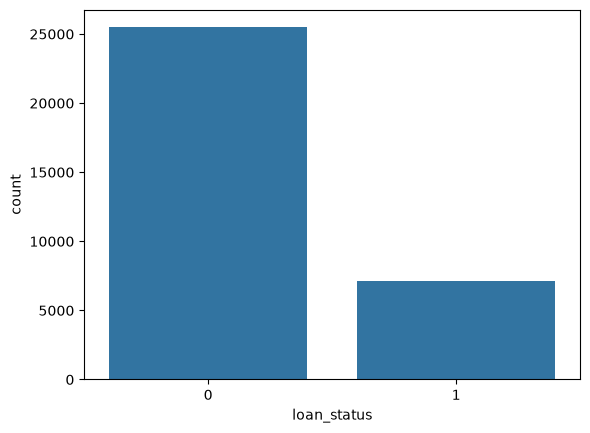

In [12]:
sns.countplot(x = 'loan_status', data =df)

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


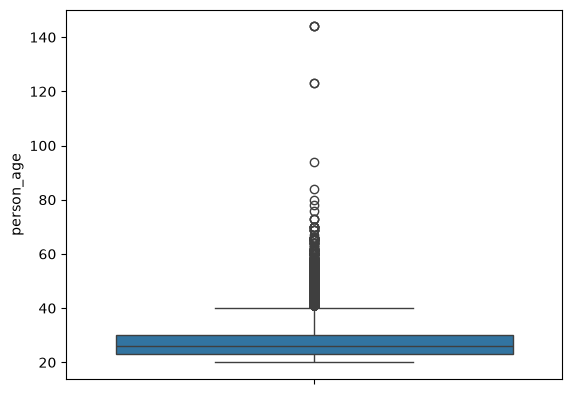

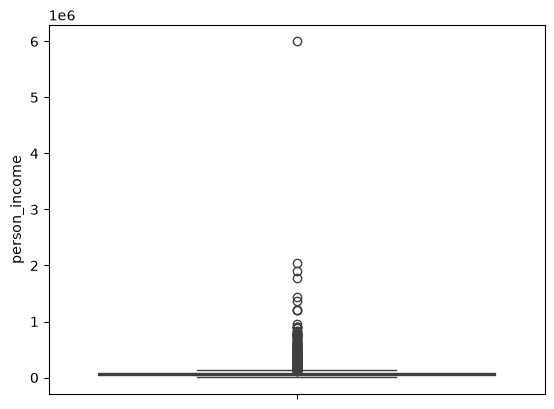

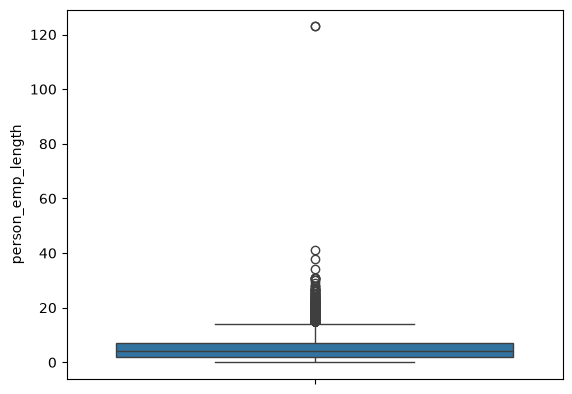

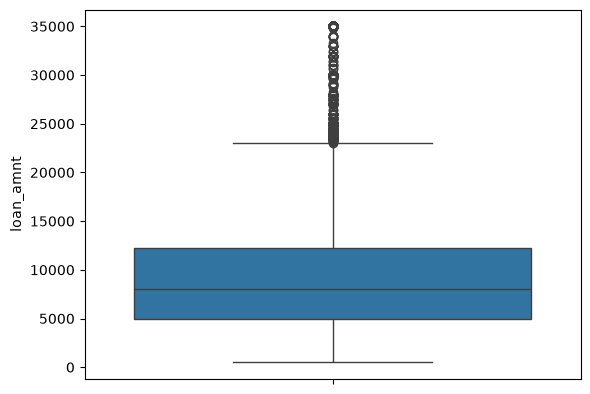

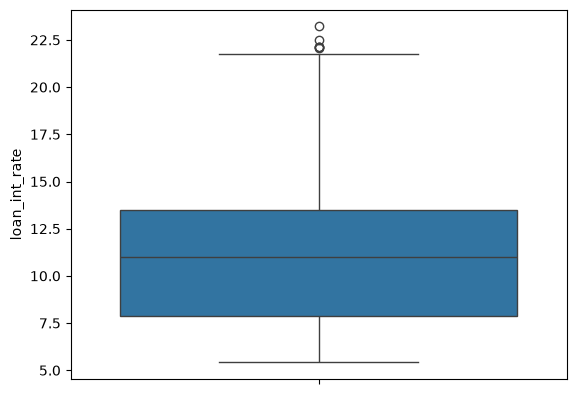

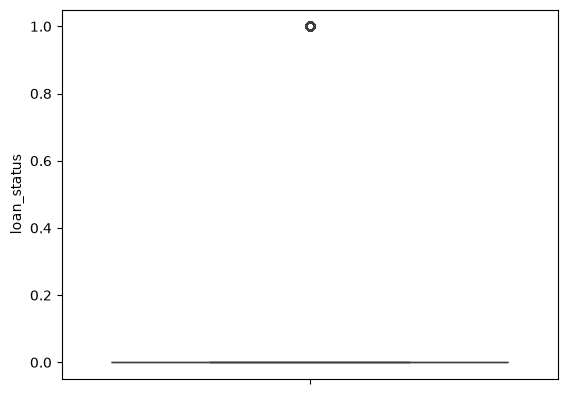

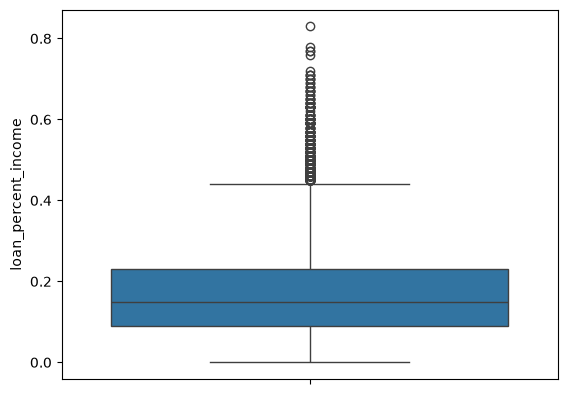

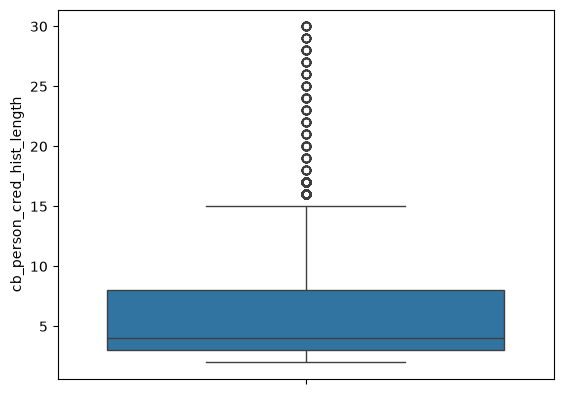

In [14]:
numerical_cols = df.select_dtypes(include = np.number).columns
for i in numerical_cols:
    sns.boxplot(df[i])
    plt.show()

In [15]:
(df["person_age"]>100).sum()

np.int64(5)

In [16]:
(df["person_emp_length"]>60).sum()

np.int64(2)

<Axes: >

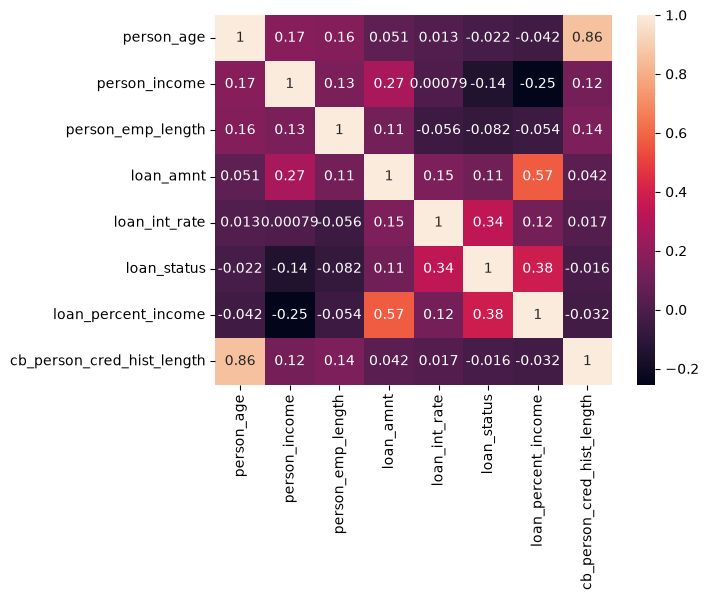

In [17]:
sns.heatmap(df.corr(numeric_only = True),annot = True)

In [18]:
df_copy = df.copy()
print(f"Original Rows: {df_copy.shape[0]}")
df_copy.drop_duplicates(inplace = True)
print(f"Rows after removing duplicates : {df_copy.shape[0]}")
df_copy = df_copy[df_copy["person_age"]>=18]
df_copy = df_copy[df_copy["person_age"]<=100]
df_copy = df_copy[df_copy["person_emp_length"]<=60]
df_copy = df_copy[df_copy['loan_amnt']>0]


Original Rows: 32581
Rows after removing duplicates : 32416


In [19]:
df_copy.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,31522.0,27.742529,6.218713,20.00,23.00,26.00,30.00,94.00
person_income,31522.0,66501.683935,52752.156211,4000.00,39438.00,56000.00,80000.00,2039784.00
person_emp_length,31522.0,4.782850,4.037343,0.00,2.00,4.00,7.00,41.00
loan_amnt,31522.0,9663.771334,6334.787700,500.00,5000.00,8000.00,12500.00,35000.00
loan_int_rate,28495.0,11.045220,3.230786,5.42,7.90,10.99,13.48,23.22
loan_status,31522.0,0.215944,0.411482,0.00,0.00,0.00,0.00,1.00
loan_percent_income,31522.0,0.169658,0.106296,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,31522.0,5.816097,4.063622,2.00,3.00,4.00,8.00,30.00


In [20]:
print("Loan interest rate range  from (min:5.42 and max : 23.22")

Loan interest rate range  from (min:5.42 and max : 23.22


In [21]:

X = df_copy.drop('loan_status', axis=1)
y = df_copy['loan_status']


In [22]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42,stratify = y)

In [23]:
numeric_cols = ['person_age','person_income','person_emp_length','loan_amnt','loan_int_rate','loan_percent_income','cb_person_cred_hist_length']
categorical_cols = ['person_home_ownership','loan_intent','cb_person_default_on_file']

In [24]:
y_train.value_counts()
neg,pos = np.bincount(y_train)
scale_weigths = neg/pos

In [25]:
scale_weigths

np.float64(3.6312213039485766)

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
preprocessor_lr = ColumnTransformer(
    transformers = [
        ('num',Pipeline([('imputer',SimpleImputer(strategy = 'median')),
                         ('scaler',StandardScaler())
                        ]),numeric_cols),
        ('cat',Pipeline([('imputer',SimpleImputer(strategy = "constant",fill_value="Missing")),
                         ('onehot',OneHotEncoder(handle_unknown = 'ignore'))
                        ]),categorical_cols)
    ])


In [27]:
preprocessor_xg = ColumnTransformer(
    transformers = [
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy = 'median'))
        ]),numeric_cols),
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy = "constant",fill_value = "Missing")),
            ('onehot',OneHotEncoder(handle_unknown = 'ignore'))
        ]),categorical_cols)
    ])

In [28]:
from sklearn.model_selection import StratifiedKFold
cv = StratifiedKFold(n_splits = 5,shuffle = True, random_state =42)
scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy','precision':'precision','recall':'recall','f1':'f1'}


In [29]:
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor',preprocessor_lr),
    ("classifier",LogisticRegression(max_iter = 1000,class_weight = "balanced",random_state =42))
])

In [30]:
from xgboost import XGBClassifier
xgb_cv_pipeline =Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(
        n_estimators = 300,max_depth = 5,learning_rate = 0.1,
        scale_pos_weight= scale_weigths,random_state = 42,n_jobs = -1,
    ))
])


In [31]:
from sklearn.model_selection import cross_validate
for cv_name,pipe in [("Logistic Regression",lr_cv_pipeline),
                     ("XGBoost",xgb_cv_pipeline)]:
    cv_results = cross_validate(pipe,X_train,y_train,cv = cv,scoring = scoring,n_jobs = -1)
    print(cv_name)
    print(f"ROC-AUC:{cv_results['test_roc_auc'].mean()}")
    print(f"Accuracy : {cv_results['test_accuracy'].mean()}")
    print(f"Precision : {cv_results['test_precision'].mean()}")
    print(f"Recall : {cv_results['test_recall'].mean()}")
    print(f"F1 : {cv_results['test_f1'].mean()}")
    
    


Logistic Regression
ROC-AUC:0.8499208626236461
Accuracy : 0.7704320795166327
Precision : 0.4804081129180475
Recall : 0.7682277318640954
F1 : 0.5910836669402715
XGBoost
ROC-AUC:0.9377025166227704
Accuracy : 0.902208846898434
Precision : 0.7677848373601097
Recall : 0.784573002754821
F1 : 0.7759779549639861


In [32]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor',preprocessor_lr),
    ('classifier',LogisticRegression(class_weight = "balanced"))
])
baseline_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [33]:
def evaluate_model(model_name,model,X_test,y_test):
    pass

In [34]:
xg_model = Pipeline([
    ('preprocessor',preprocessor_xg),
    ('classifier',XGBClassifier(learning_rate = 0.1,
                                scale_pos_weight = scale_weigths,random_state =42))
])
xg_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [35]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,precision_recall_curve,classification_report
def evaluate_model(model_name,model,X_test,y_test,threshold = None):
    y_pred = model.predict(X_test)
    y_pred_prob = model.predict_proba(X_test)[:,1]
    if threshold:
        y_pred = (y_pred_prob>threshold).astype(int)
    else:
        y_pred  = model.predict(X_test)
    
    accuracy = accuracy_score(y_test,y_pred)
    precision_s = precision_score(y_test,y_pred)
    recall_s = recall_score(y_test,y_pred)
    f1 = f1_score(y_test,y_pred)
    cm = confusion_matrix(y_test,y_pred)
    class_report = classification_report(y_test,y_pred)
    print(f"Accuracy : {accuracy:.2f}")
    print(f"Precision : {precision_s:.2f}")
    print(f"Recall: {recall_s:.2f}")
    print(f"F1 : {f1:.2f}")
    print()
    print(f"{model_name} Classification Report:")
    print(class_report)
    sns.heatmap(cm,annot = True,fmt = "d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()
    precisions,recalls,threshold = precision_recall_curve(y_test,y_pred_prob)
    plt.plot(recalls,precisions)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

Accuracy : 0.78
Precision : 0.50
Recall: 0.79
F1 : 0.61

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.78      0.85      4943
           1       0.50      0.79      0.61      1362

    accuracy                           0.78      6305
   macro avg       0.71      0.79      0.73      6305
weighted avg       0.84      0.78      0.80      6305



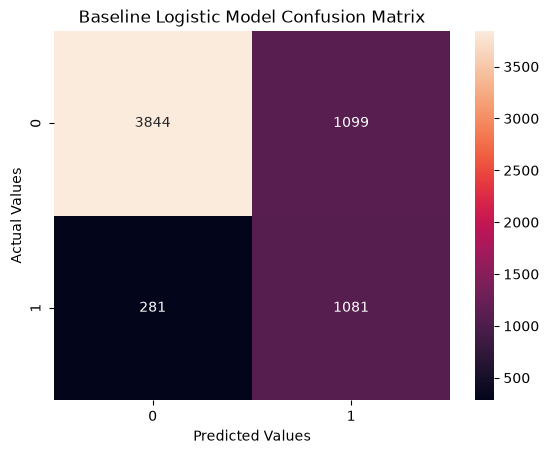

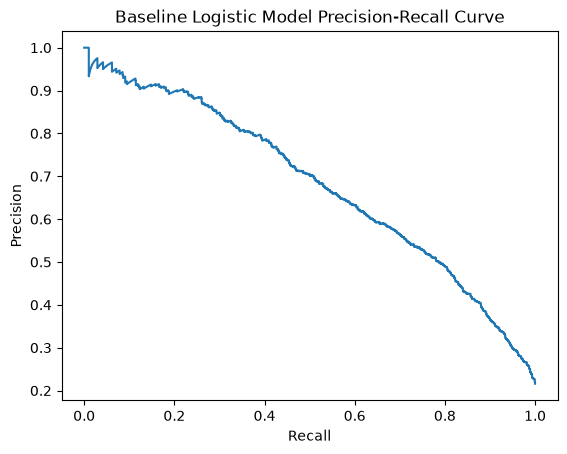

In [36]:
evaluate_model("Baseline Logistic Model",baseline_model,X_test,y_test)

In [37]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform,randint
param_grid = {
    "classifier__n_estimators":randint(150,600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01,0.5),
    "classifier__subsample": uniform(0.6,0.4),
    "classifier__colsample_bytree":uniform(0.6,0.4),
    "classifier__min_child_weight": randint(1,10),
    "classifier__gamma": uniform(0,5)
}




In [38]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter = 150,
    cv = cv,
    scoring = "average_precision",
    n_jobs = -1,
    verbose = 1
)
random_search.fit(X_train,y_train)
best_model = random_search.best_estimator_


Fitting 5 folds for each of 150 candidates, totalling 750 fits


In [39]:
random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8876221538298881),
 'classifier__gamma': np.float64(2.0413641977360744),
 'classifier__learning_rate': np.float64(0.06875481946957455),
 'classifier__max_depth': 6,
 'classifier__min_child_weight': 2,
 'classifier__n_estimators': 400,
 'classifier__subsample': np.float64(0.8976065819895893)}

In [40]:
random_search.best_score_

np.float64(0.8847702501788304)

Accuracy : 0.78
Precision : 0.50
Recall: 0.79
F1 : 0.61

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.78      0.85      4943
           1       0.50      0.79      0.61      1362

    accuracy                           0.78      6305
   macro avg       0.71      0.79      0.73      6305
weighted avg       0.84      0.78      0.80      6305



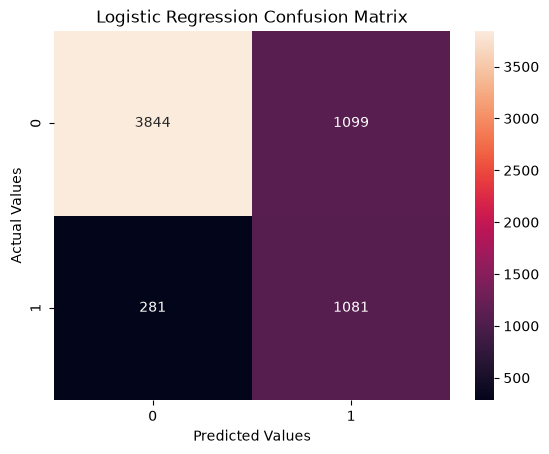

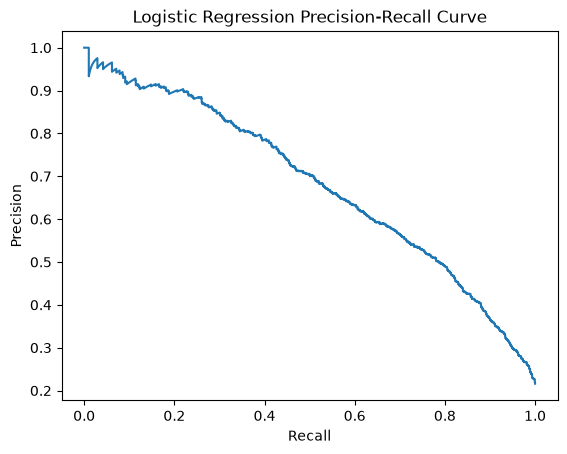

In [41]:
evaluate_model("Logistic Regression",baseline_model,X_test,y_test)

Accuracy : 0.91
Precision : 0.79
Recall: 0.79
F1 : 0.79

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.94      0.94      4943
           1       0.79      0.79      0.79      1362

    accuracy                           0.91      6305
   macro avg       0.86      0.87      0.86      6305
weighted avg       0.91      0.91      0.91      6305



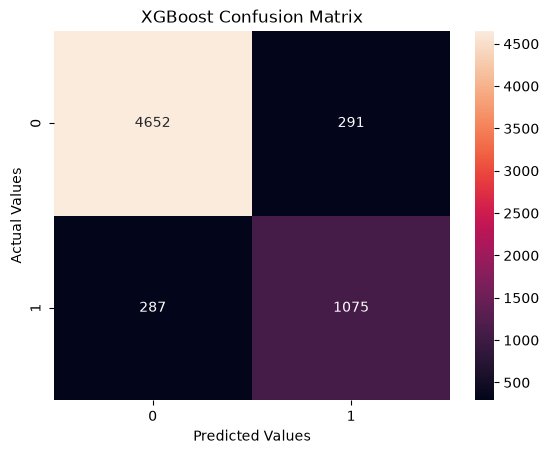

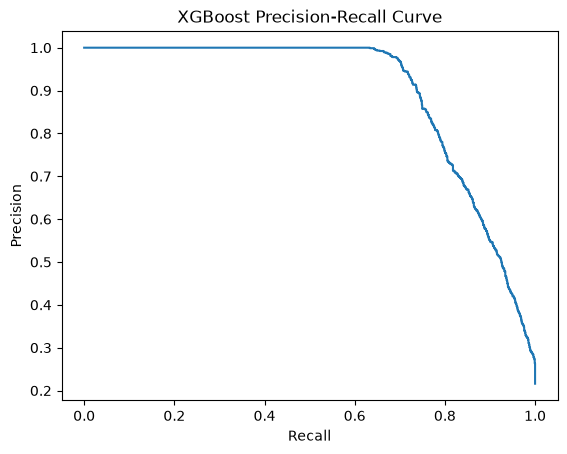

In [42]:
evaluate_model("XGBoost",random_search,X_test,y_test)

C:\Users\anmol\anaconda3\envs\pytorch\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\anmol\anaconda3\envs\pytorch\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\anmol\anaconda3\envs\pytorch\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0

Accuracy : 0.78
Precision : 0.00
Recall: 0.00
F1 : 0.00

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4943
           1       0.00      0.00      0.00      1362

    accuracy                           0.78      6305
   macro avg       0.39      0.50      0.44      6305
weighted avg       0.61      0.78      0.69      6305



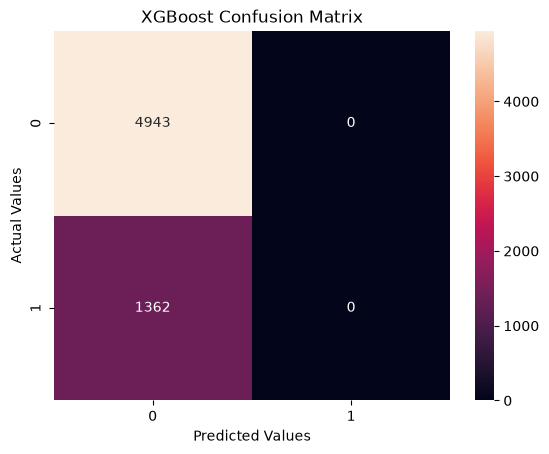

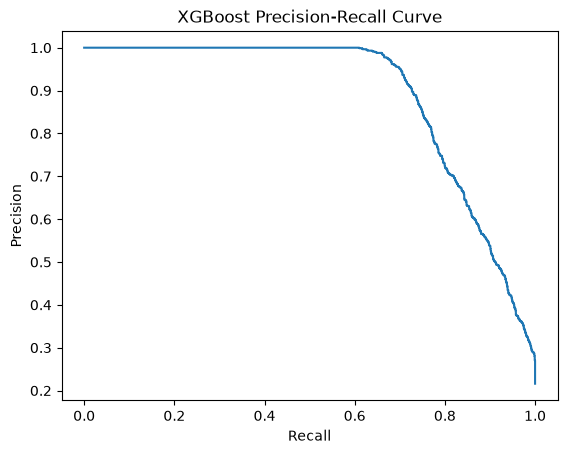

In [43]:
prob = xg_model.predict_proba(X_test)[:,1]
precisions,recalls,thresholds = precision_recall_curve(y_test,prob)
f1 = 2*(precisions-recalls)/(precisions+recalls+1e-9)
best = np.argmax(f1[:-1])
best_threshold = thresholds[best]
evaluate_model("XGBoost",xg_model,X_test,y_test,best_threshold)

In [44]:
from sklearn.calibration import CalibratedClassifierCV
best_model = random_search.best_estimator_

calibrated_model = CalibratedClassifierCV(
    best_model,
    method = "sigmoid",
    cv = 5
)
calibrated_model.fit(X_train,y_train)
print("Calibration completed successfully !")

Calibration completed successfully !


In [45]:
uncalibrated = xg_model.predict_proba(X_test)[:,1]
uncalibrated
calibrated = calibrated_model.predict_proba(X_test)[:,1]
calibrated

array([0.07153121, 0.0305208 , 0.93801816, ..., 0.43148707, 0.01977513,
       0.01428832], shape=(6305,))

In [51]:
from sklearn.calibration import calibration_curve
actual_uncal,predicted_uncal = calibration_curve(y_test,uncalibrated,n_bins = 10)
actual_cal,predicted_cal = calibration_curve(y_test,calibrated,n_bins = 10)

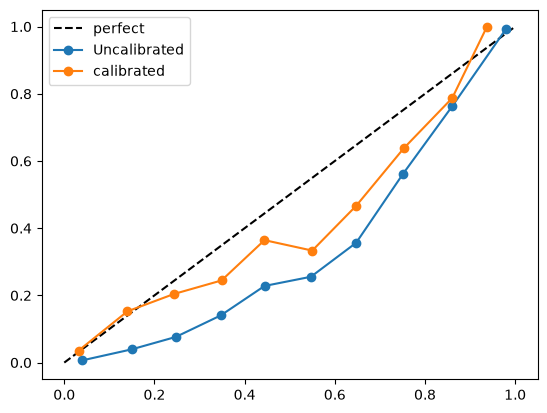

In [52]:
plt.plot([0,1],[0,1],'k--',label = "perfect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "Uncalibrated"
)
plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "calibrated"
)
plt.legend()


In [53]:
!pip install shap

In [54]:
import shap

In [55]:
xgb_classifier = xg_model.named_steps['classifier']

In [56]:
X_test_transformed = xg_model.named_steps['preprocessor'].transform(X_test)

In [57]:
feature_names =   xg_model.named_steps['preprocessor'].get_feature_names_out()

In [58]:
X_test_df = pd.DataFrame(X_test_transformed,columns = feature_names)
X_test_df

,num__person_age,num__person_income,num__person_emp_length,num__loan_amnt,num__loan_int_rate,num__loan_percent_income,num__cb_person_cred_hist_length,cat__person_home_ownership_MORTGAGE,cat__person_home_ownership_OTHER,cat__person_home_ownership_OWN,cat__person_home_ownership_RENT,cat__loan_intent_DEBTCONSOLIDATION,cat__loan_intent_EDUCATION,cat__loan_intent_HOMEIMPROVEMENT,cat__loan_intent_MEDICAL,cat__loan_intent_PERSONAL,cat__loan_intent_VENTURE,cat__cb_person_default_on_file_N,cat__cb_person_default_on_file_Y
0,24.0,30000.0,1.0,15000.0,15.68,0.50,3.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,23.0,60000.0,6.0,25600.0,10.99,0.43,4.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,29.0,18000.0,2.0,3600.0,15.27,0.20,6.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,32.0,130000.0,7.0,13000.0,12.69,0.10,8.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,23.0,45288.0,7.0,20500.0,9.25,0.45,2.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6300,21.0,75000.0,5.0,20000.0,13.11,0.27,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
6301,29.0,265000.0,2.0,25000.0,11.26,0.09,10.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
6302,25.0,48996.0,8.0,5000.0,9.88,0.10,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
6303,27.0,115000.0,11.0,8000.0,7.51,0.07,7.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [59]:
explainer = shap.TreeExplainer(xgb_classifier)

In [60]:
shap_values = explainer.shap_values(X_test_df)
shap_values

array([[ 3.2769747e-02,  6.6528112e-02,  2.3832649e-01, ...,
         6.8493932e-02, -3.3901434e-02,  0.0000000e+00],
       [ 3.2029739e-03, -8.8768291e-01, -6.8320535e-02, ...,
         1.0041841e-01, -6.2648542e-02,  0.0000000e+00],
       [ 7.4838698e-02,  3.3895288e+00,  2.6992279e-01, ...,
         2.9714018e-02, -1.2515711e-02,  0.0000000e+00],
       ...,
       [ 7.7890888e-02,  7.0787483e-01,  1.0061085e-01, ...,
         2.2186683e-01, -8.5258521e-02,  0.0000000e+00],
       [ 3.1367093e-02, -8.8462120e-01,  2.7302042e-02, ...,
         1.8441725e-01, -8.5075051e-02,  0.0000000e+00],
       [-2.9204661e-02, -6.6957790e-01,  1.6237734e-02, ...,
         1.9555695e-01, -8.7382533e-02,  0.0000000e+00]],
      shape=(6305, 19), dtype=float32)

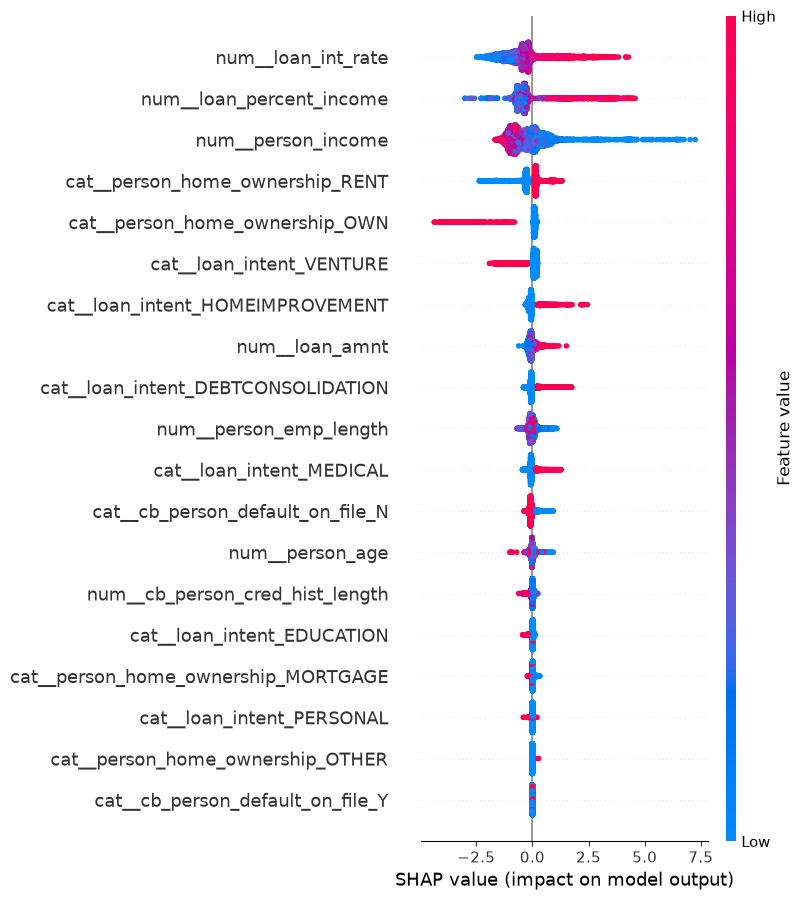

In [61]:
shap.summary_plot(shap_values,X_test_df)

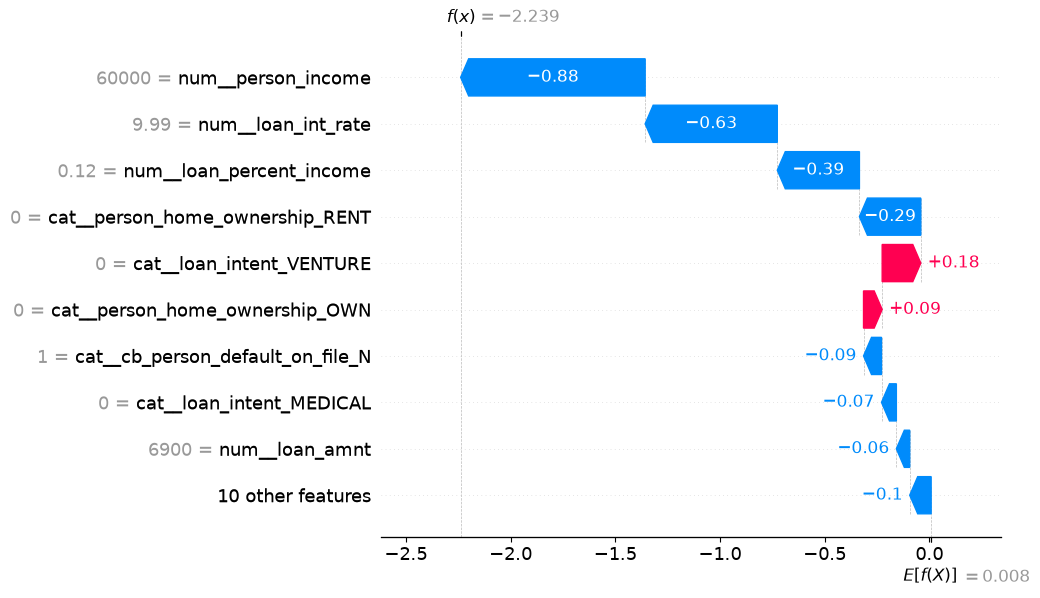

In [62]:
row_index = 5
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)



In [63]:
y_pred = random_search.predict(X_test)

In [64]:
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred




In [65]:
result_df

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,actual,predicted
14455,24,30000,OWN,1.0,MEDICAL,E,15000,15.68,0.50,N,3,1,0
8701,23,60000,MORTGAGE,6.0,EDUCATION,C,25600,NaN,0.43,N,4,0,0
19804,29,18000,RENT,2.0,EDUCATION,C,3600,15.27,0.20,N,6,1,1
27252,32,130000,MORTGAGE,7.0,MEDICAL,B,13000,12.69,0.10,N,8,0,0
5610,23,45288,MORTGAGE,7.0,DEBTCONSOLIDATION,B,20500,9.25,0.45,N,2,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
11661,21,75000,MORTGAGE,5.0,PERSONAL,C,20000,13.11,0.27,Y,2,0,0
27837,29,265000,MORTGAGE,2.0,PERSONAL,B,25000,11.26,0.09,N,10,0,0
17192,25,48996,MORTGAGE,8.0,MEDICAL,B,5000,9.88,0.10,N,2,1,1
26858,27,115000,MORTGAGE,11.0,MEDICAL,A,8000,7.51,0.07,N,7,0,0


In [66]:
y_pred = random_search.predict(X_test)

In [67]:
result_df = X_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [68]:
false_positive = result_df[(result_df['actual'] == 0) & (result_df['predicted'] == 1)]
false_negative = result_df[(result_df['actual'] == 1) & (result_df['predicted'] == 0)]

In [69]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : { len(false_negative)}")

False Positive : 291
False Negative : 287


In [70]:
import joblib
joblib.dump(calibrated_model,"credit_risk_model.pkl")

['credit_risk_model.pkl']

In [75]:
joblib.dump(best_threshold,"best_threshold.pkl")

['best_threshold.pkl']

In [74]:
from sklearn.metrics import precision_recall_curve
import numpy as np
calibrated_proba = calibrated_model.predict_proba(X_test)[:,1]
precisions,recalls,thresholds = precision_recall_curve(y_test,calibrated_proba)
f1_scores = 2*(precisions*recalls)/(precisions+recalls+1e-9)
best_threshold = thresholds[np.argmax(f1_scores[:-1])]
print("New threshold : ",best_threshold)

New threshold :  0.6338306487247757
